In [19]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pandas as pd
import numpy as np
from safetensors.torch import load_file

# Configuration
RESULTS_DIR = Path("../results/model_comparison/similarities")
# Base path for ID measures (results directory)
ID_RESULTS_BASE = Path("../results")
PLOTS_DIR = Path("../plots/models_similarity")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Identifiers must match what was used in the script (split by /)
# These are used for similarity filenames
MODEL_A_ID = "llava-1.5-7b-hf"  # Finetuned (Rows)
MODEL_B_ID = "llava-v1.5-7b-pretrained-lbasile" # Pretrained (Columns)

# Mapping from similarity IDs to folder names for ID data loading
ID_MODEL_DIRS = {
    # Key should match MODEL_A_ID / B_ID or just map clearly
    "Finetuned": "llava-1.5-7b-hf",
    "Pretrained": "llava-v1.5-mlp2x-336px-pretrain-vicuna-7b-v1.5"
}

# Explicitly map the IDs to "Finetuned" and "Pretrained" roles
MODEL_ROLES = {
    MODEL_A_ID: "Finetuned",
    MODEL_B_ID: "Pretrained"
}

DATASETS = {
    "cocoqa_txt": "Text QA",
    "cocoqa_img": "Image QA"
}

MEASURES = {
    "neighborhood_overlap": "Neighborhood Overlap",
    "linear_cka": "Linear CKA",
    "distance_correlation": "Distance Correlation"
}

In [20]:
def load_data(dataset_key, measure_key):
    # Filename format: {dataset}_{model_a}_vs_{model_b}_{measure}.safetensors
    filename = f"{dataset_key}_{MODEL_A_ID}_vs_{MODEL_B_ID}_{measure_key}.safetensors"
    path = RESULTS_DIR / filename
    try:
        data = load_file(str(path))
        tensor = data[measure_key]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"Error loading {filename}: {e}")
        return None

def load_id_data(dataset_key, role_key):
    """
    Load Intrinsic Dimension data.
    dataset_key: 'cocoqa_img' or 'cocoqa_txt'
    role_key: 'Pretrained' or 'Finetuned'
    """
    model_dir = ID_MODEL_DIRS[role_key]
    # Path construction: results/{dataset}/models_data_measures/{model_dir}/id_...
    path = ID_RESULTS_BASE / dataset_key / "models_data_measures" / model_dir / "id_16_100_output_layer_last.safetensors"
    
    try:
        data = load_file(str(path))
        tensor = data["layers_intrinsic_dimension"]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"Error loading ID data from {path}: {e}")
        return None

def plot_model_comparison(measure_key, measure_title):
    # Load similarity data for both datasets
    sim_txt = load_data("cocoqa_txt", measure_key)
    sim_img = load_data("cocoqa_img", measure_key)
    
    # Load ID data for both models for both datasets
    # Structure: 
    # For Text QA dataset: we need ID for both Pretrained and Finetuned on Text data
    id_txt_pm = load_id_data("cocoqa_txt", "Pretrained")
    id_txt_fm = load_id_data("cocoqa_txt", "Finetuned")
    
    # For Image QA dataset: we need ID for both models on Image data
    id_img_pm = load_id_data("cocoqa_img", "Pretrained")
    id_img_fm = load_id_data("cocoqa_img", "Finetuned")
    
    # Check for missing data (basic check, could be more granular)
    if sim_txt is None and sim_img is None:
        print(f"Skipping plot for {measure_title} due to missing similarity data.")
        return

    # Setup figure
    fig = plt.figure(figsize=(20, 10))
    
    # Outer Grid: Top Area (Plots), Bottom Area (Colorbar)
    gs_outer = gridspec.GridSpec(2, 1, height_ratios=[1, 0.08], hspace=0.25)
    
    # Top Area: Split into Left (Text QA) and Right (Image QA)
    gs_main = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0], wspace=0.2)
    
    # List of datasets to plot
    # Each entry: (Dataset Title, Sim Matrix, ID_Pretrained (X-axis), ID_Finetuned (Y-axis))
    datasets_list = [
        ("Text QA", sim_txt, id_txt_pm, id_txt_fm), 
        ("Image QA", sim_img, id_img_pm, id_img_fm)
    ]
    
    heatmap_axes = []
    
    for idx, (ds_title, sim_data, id_pm, id_fm) in enumerate(datasets_list):
        if sim_data is None:
            continue
            
        # Inner Grid for each dataset: 2x2
        # R0: [Top Plot (Pretrained ID), Empty]
        # R1: [Heatmap, Right Plot (Finetuned ID)]
        gs_inner = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs_main[idx],
                                                    width_ratios=[6, 1], height_ratios=[1, 6],
                                                    wspace=0.03, hspace=0.03)
        
        ax_top = fig.add_subplot(gs_inner[0, 0])
        ax_main = fig.add_subplot(gs_inner[1, 0])
        ax_right = fig.add_subplot(gs_inner[1, 1])
        
        # Share axes
        ax_top.sharex(ax_main)
        ax_right.sharey(ax_main)

        # 1. Main Heatmap
        # Rows = Finetuned, Cols = Pretrained
        sns.heatmap(
            sim_data,
            ax=ax_main,
            cmap="viridis",
            vmin=0, vmax=1,
            square=False,
            cbar=False
        )
        heatmap_axes.append(ax_main)
        
        # Centers for 1D plots
        x_centers = np.arange(len(id_pm)) + 0.5
        y_centers = np.arange(len(id_fm)) + 0.5
        
        # 2. Top Plot (Pretrained ID - X axis)
        # Use Blue-ish color
        ax_top.plot(x_centers, id_pm, color='#377eb8', lw=2) 
        ax_top.fill_between(x_centers, id_pm, color='#377eb8', alpha=0.3)
        
        # Formatting Top Plot
        sns.despine(ax=ax_top, bottom=True, left=False)
        ax_top.tick_params(bottom=False, labelbottom=False)
        ax_top.tick_params(axis='y', labelsize=8)
        ax_top.set_ylabel("ID", fontsize=9, rotation=0, labelpad=15)
        
        # 3. Right Plot (Finetuned ID - Y axis)
        # Use Red-ish color
        ax_right.plot(id_fm, y_centers, color='#e41a1c', lw=2)
        ax_right.fill_betweenx(y_centers, id_fm, color='#e41a1c', alpha=0.3)
        
        # Formatting Right Plot
        sns.despine(ax=ax_right, left=True, bottom=False)
        ax_right.tick_params(left=False, labelleft=False)
        ax_right.tick_params(axis='x', labelsize=8)
        ax_right.set_xlabel("ID", fontsize=9)
        
        # Formatting Main Axis
        # ax_main.set_title(f"Dataset: {ds_title}", fontsize=18, pad=10, fontweight='medium') # Moved to top plot
        ax_main.set_xlabel("Pretrained Model Layers", fontsize=13, labelpad=8)
        if idx == 0:
            ax_main.set_ylabel("Finetuned Model Layers", fontsize=13, labelpad=8)
        
        ax_main.invert_yaxis() # 0 at bottom
        
        # Ticks
        num_layers = sim_data.shape[0]
        ticks = range(0, num_layers, 5)
        ax_main.set_xticks([t + 0.5 for t in ticks])
        ax_main.set_xticklabels(ticks, fontsize=11)
        ax_main.set_yticks([t + 0.5 for t in ticks])
        ax_main.set_yticklabels(ticks, fontsize=11)
        
        # Add Dataset Title on TOP AXIS instead of main axis to clear overlap
        ax_top.set_title(f"{ds_title}", fontsize=18, pad=13, fontweight='medium')

    # Colorbar (Shared for both subplots)
    cax = fig.add_subplot(gs_outer[1])
    if heatmap_axes:
        mappable = heatmap_axes[-1].collections[0]
        plt.colorbar(mappable, cax=cax, orientation='horizontal', label=measure_title) # Removed shrink to fill width

    plt.suptitle(f"{measure_title}: Pretrained vs Finetuned Layer Similarity",#\n(with Intrinsic Dimension Marginals)", 
                 fontsize=22, fontweight='bold', y=0.98)
    
    # Save
    save_path = PLOTS_DIR / f"models_similarity_{measure_key}_with_id.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"Saved plot to {save_path}")
    plt.show()

Saved plot to ../plots/models_similarity/models_similarity_neighborhood_overlap_with_id.png


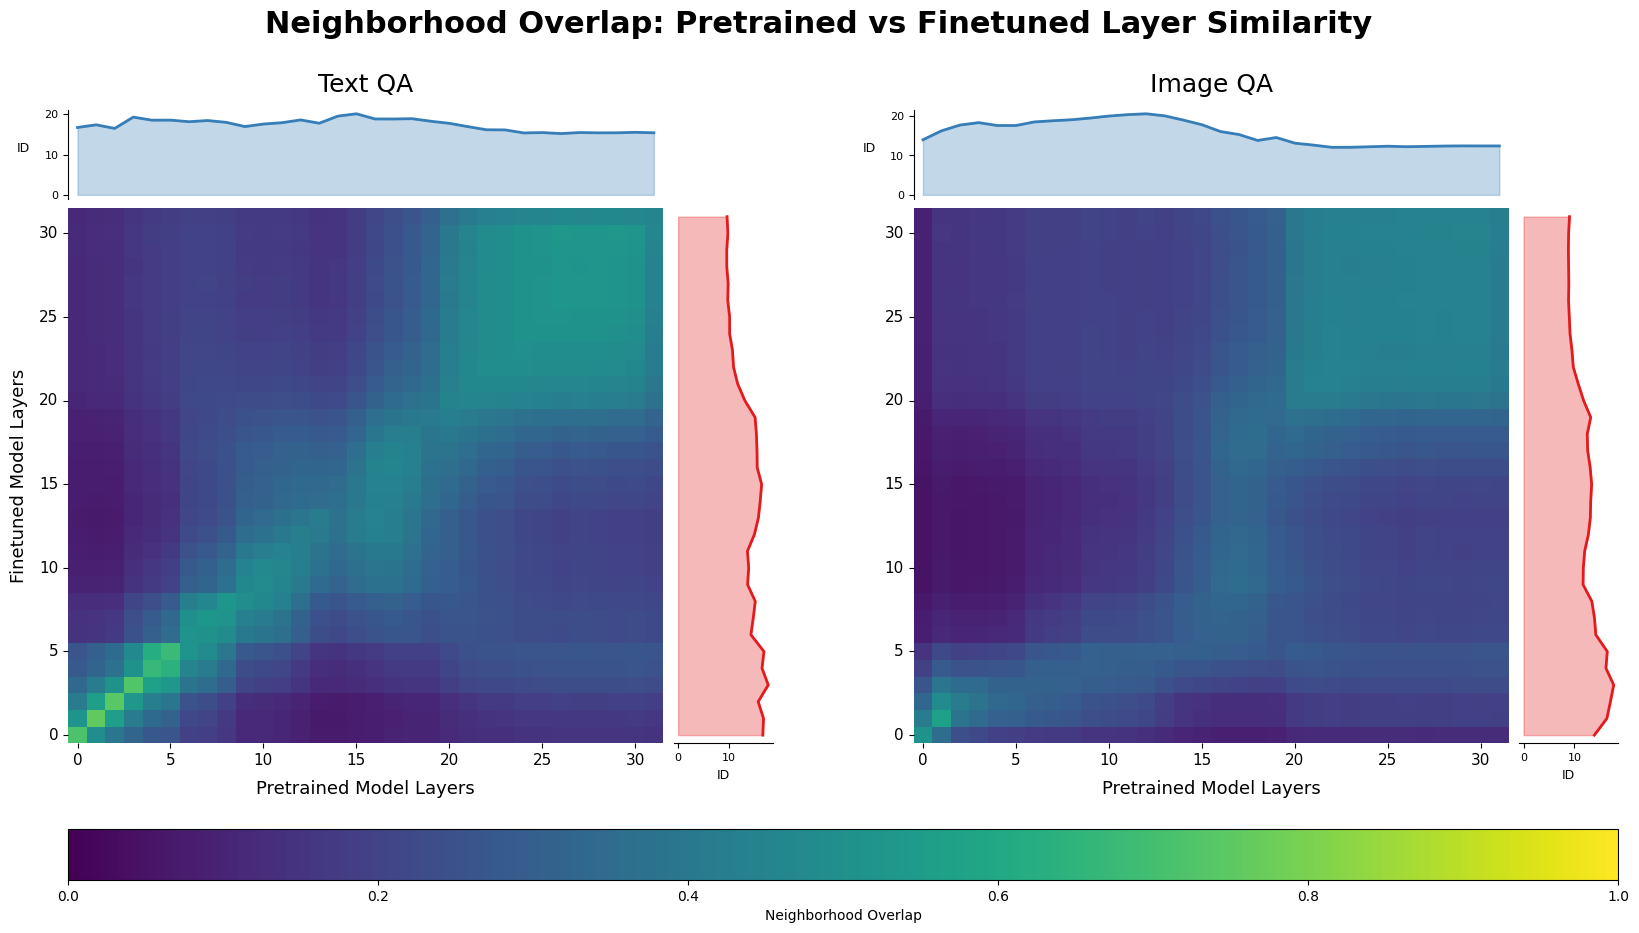

Saved plot to ../plots/models_similarity/models_similarity_linear_cka_with_id.png


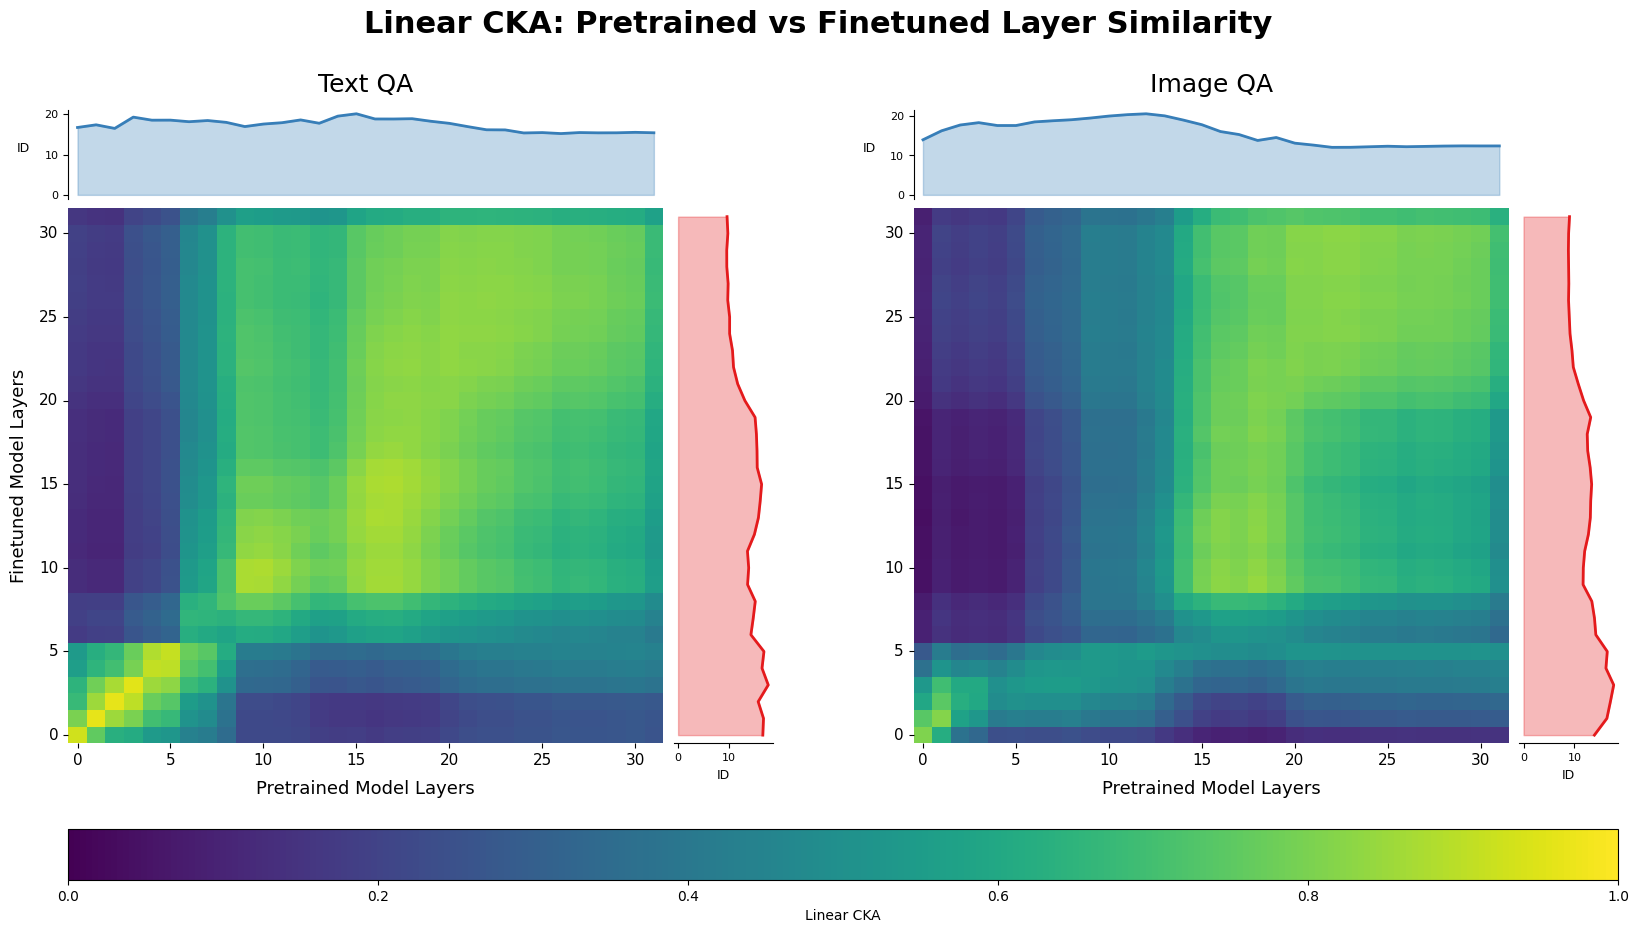

Saved plot to ../plots/models_similarity/models_similarity_distance_correlation_with_id.png


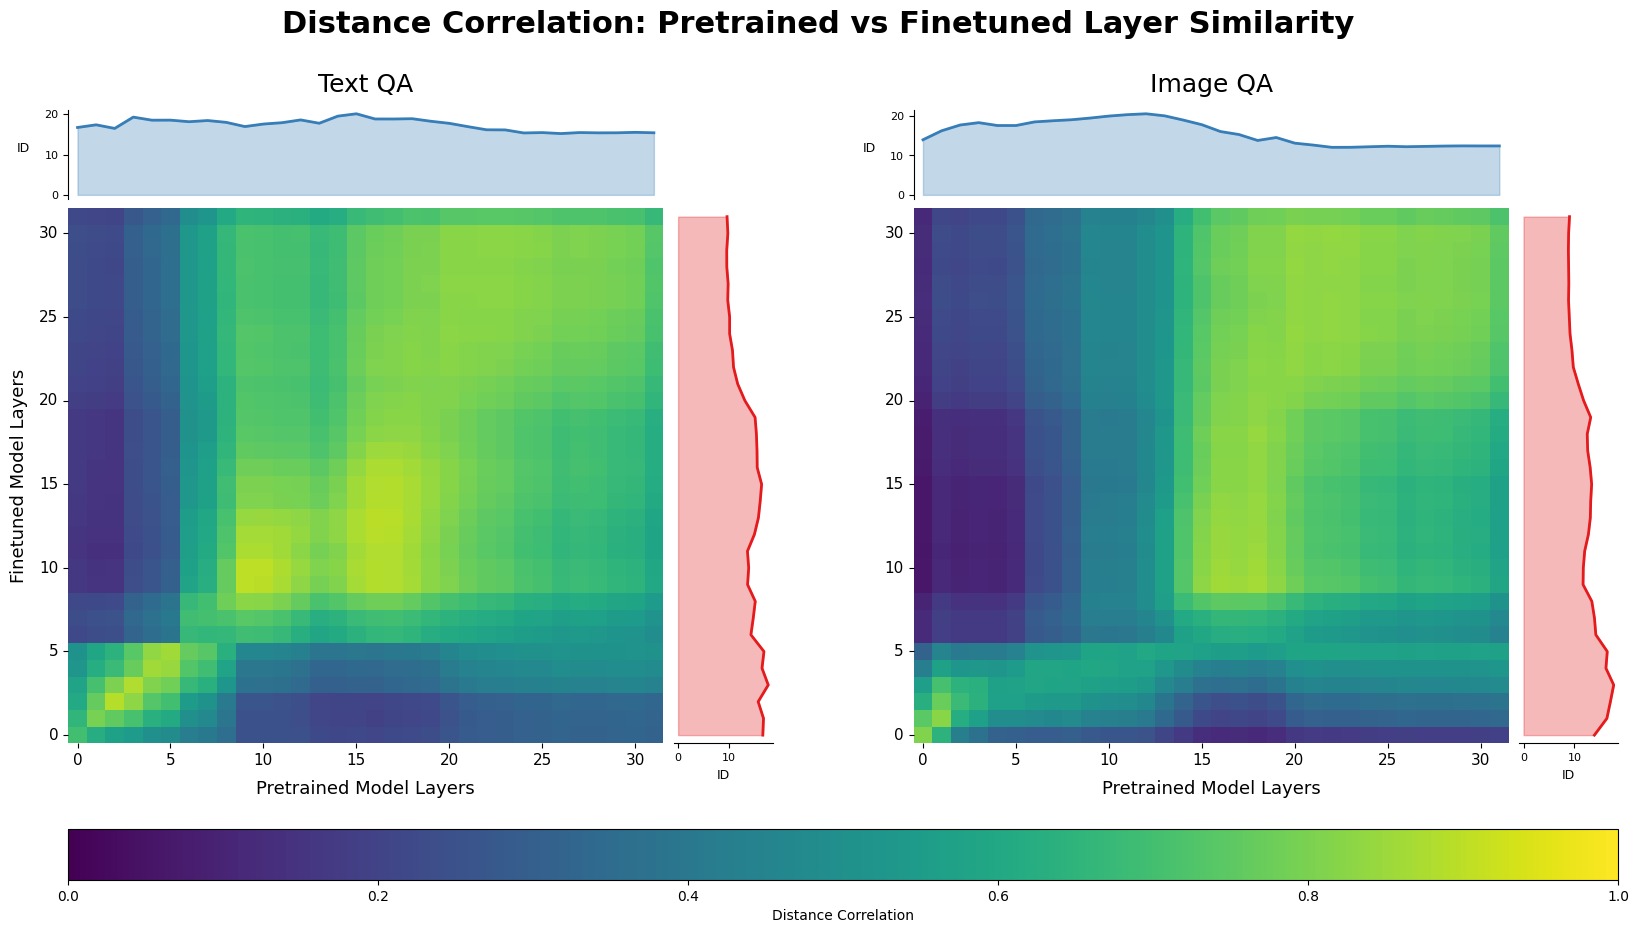

In [21]:
# Generate plots for all measures
for key, title in MEASURES.items():
    plot_model_comparison(key, title)